<a href="https://colab.research.google.com/github/AuliaRestyy/machineLearning/blob/main/JS12/JS12_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "/content/drive/MyDrive/images/training"
test_dir  = "/content/drive/MyDrive/images/test"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f"Number of training samples: {len(train_img)}")
print(f"Number of testing samples: {len(test_img)}")

Number of training samples: 240
Number of testing samples: 160


In [3]:
# Preprocess images: resize and encode labels

def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

In [4]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

In [5]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

In [8]:
# Split training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
)

In [10]:
# Convert labels to numpy arrays (required for Keras)
y_train = np.array(y_train)
y_val = np.array(y_val)

In [13]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [16]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)


Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 271ms/step - accuracy: 0.7656 - loss: 1.0752 - val_accuracy: 0.9583 - val_loss: 0.7989
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 161ms/step - accuracy: 0.9740 - loss: 0.2700 - val_accuracy: 1.0000 - val_loss: 0.0026
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 150ms/step - accuracy: 0.9948 - loss: 0.0554 - val_accuracy: 0.9792 - val_loss: 0.0545
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 176ms/step - accuracy: 1.0000 - loss: 6.4074e-04 - val_accuracy: 0.9792 - val_loss: 0.0768
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 157ms/step - accuracy: 1.0000 - loss: 3.4363e-05 - val_accuracy: 0.9792 - val_loss: 0.1582
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 173ms/step - accuracy: 1.0000 - loss: 1.8926e-05 - val_accuracy: 0.9792 - val_loss: 0.2152
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 152ms/step - accuracy: 1.0000 - loss: 4.7861e-04 - val_accuracy: 0.9792 - val_loss: 0.2507
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - accuracy: 1.0000 - loss: 9.2584e-06 - val_accuracy

In [21]:
X_test_scaled = np.asarray(X_test_scaled).astype('float32')
y_test = np.asarray(y_test).astype('float32').reshape(-1)

test_loss, test_acc = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=1
)

print("Test Accuracy:", test_acc)
print("Test Loss:", test_loss)


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.8938 - loss: 0.9070
Test Accuracy: 0.893750011920929
Test Loss: 0.9070296287536621


In [22]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

print(classification_report(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
              precision    recall  f1-score   support

         0.0       0.93      0.85      0.89        80
         1.0       0.86      0.94      0.90        80

    accuracy                           0.89       160
   macro avg       0.90      0.89      0.89       160
weighted avg       0.90      0.89      0.89       160



[[68 12]
 [ 5 75]]


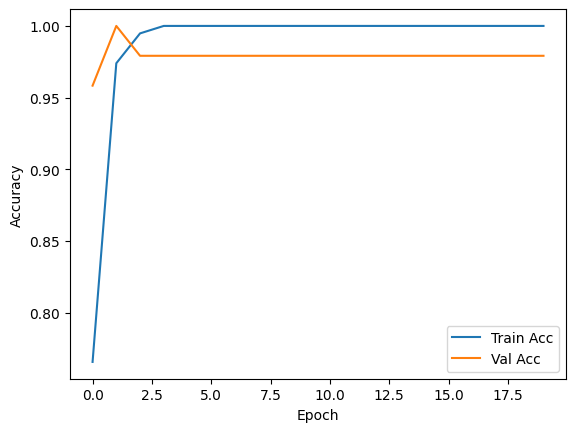

In [23]:
print(confusion_matrix(y_test, y_pred))

plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [24]:
import pickle

model.save('day_night_model.h5')
print("Model successfully saved: day_night_model.h5")

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

Model successfully saved: day_night_model.h5
